In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create output folder for saving plots and results
os.makedirs('output', exist_ok=True)

# Load dataset directly from UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')

# Save a local copy of the dataset
df.to_csv('winequality-red.csv', index=False)

print("Dataset Loaded Successfully! Shape:", df.shape)
display(df.head())

Dataset Loaded Successfully! Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Missing Values:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Quality Score Counts:
 quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


/tmp/ipykernel_3993/4026990566.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality', data=df, palette='viridis')


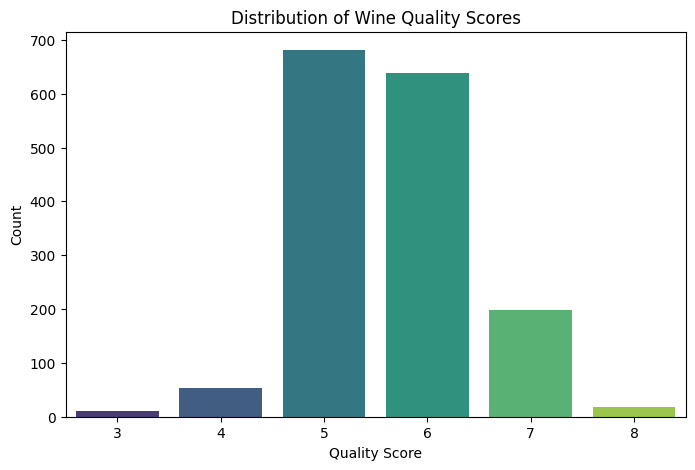

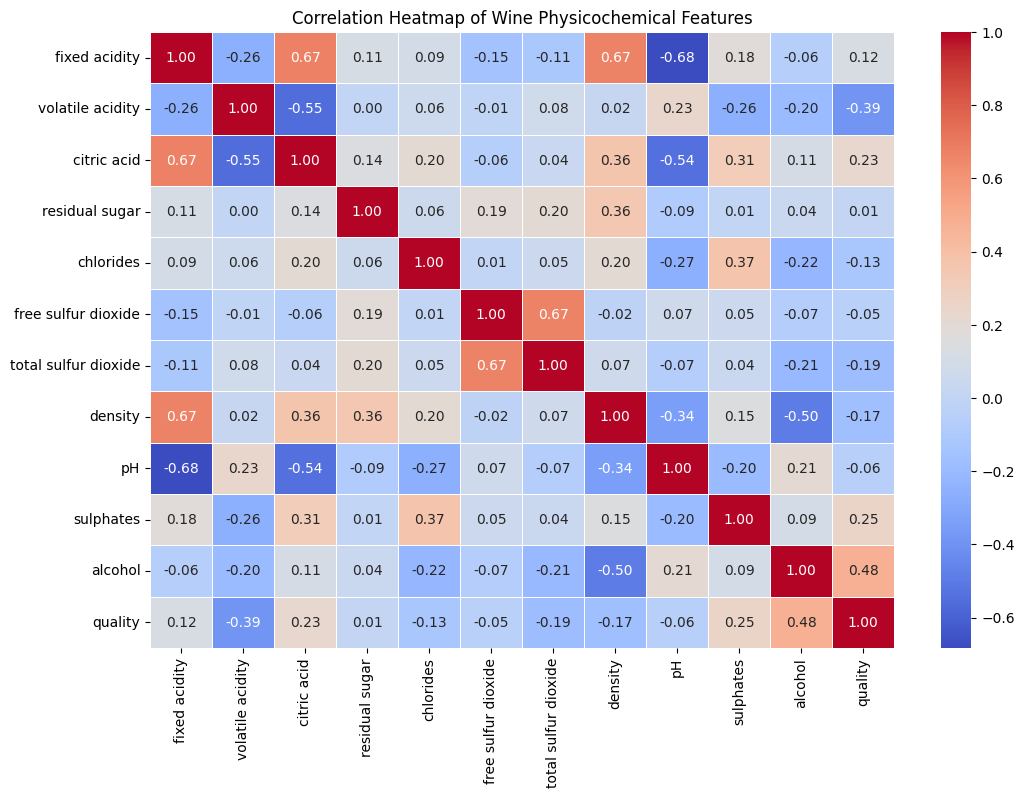

In [6]:
# Check missing values and basic info
print("Missing Values:\n", df.isnull().sum())
print("\nQuality Score Counts:\n", df['quality'].value_counts().sort_index())

# Plot 1: Distribution of Wine Quality Scores
plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=df, palette='viridis')
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.savefig('output/quality_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Wine Physicochemical Features')
plt.savefig('output/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

Binary Class Distribution:
 quality_label
0    1382
1     217
Name: count, dtype: int64
================ Random Forest ================
Accuracy: 0.9375

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96       277
           1       0.93      0.58      0.71        43

    accuracy                           0.94       320
   macro avg       0.93      0.79      0.84       320
weighted avg       0.94      0.94      0.93       320

Confusion Matrix:
 [[275   2]
 [ 18  25]] 

================ SGD Classifier ================
Accuracy: 0.8688

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       277
           1       0.51      0.47      0.49        43

    accuracy                           0.87       320
   macro avg       0.72      0.70      0.71       320
weighted avg       0.86      0.87      0.87       320

Confusion Matrix:
 [[258  19]
 [ 23

,Model,Accuracy (%)
0,Random Forest,93.75
2,Support Vector Classifier (SVC),90.00
1,SGD Classifier,86.88


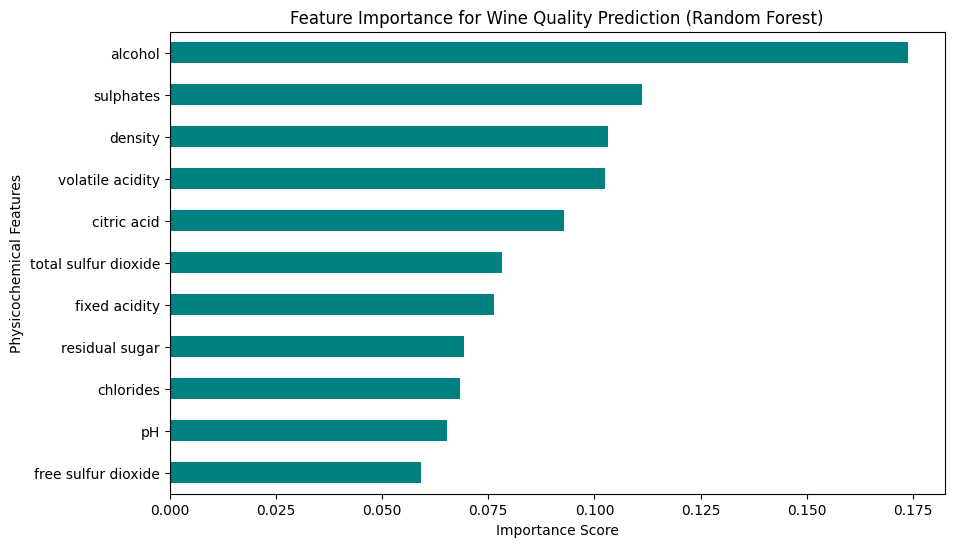

All models trained and outputs saved successfully!


In [7]:
# --- STEP 3: Feature Engineering & Preprocessing ---
# Creating binary target: 1 = Good Wine (quality >= 7), 0 = Average/Bad Wine (quality < 7)
df['quality_label'] = df['quality'].apply(lambda x: 1 if x >= 7 else 0)
print("Binary Class Distribution:\n", df['quality_label'].value_counts())

X = df.drop(['quality', 'quality_label'], axis=1)
y = df['quality_label']

# Stratified Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# --- STEP 4: Model Training & Comparison ---
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SGD Classifier': SGDClassifier(random_state=42),
    'Support Vector Classifier (SVC)': SVC(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results.append({'Model': name, 'Accuracy (%)': round(acc * 100, 2)})

    print(f"================ {name} ================")
    print(f"Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred), "\n")

# Summary Comparison Table
results_df = pd.DataFrame(results).sort_values(by='Accuracy (%)', ascending=False)
print("--- Model Comparison Summary ---")
display(results_df)


# --- STEP 5: Feature Importance ---
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='teal')
plt.title('Feature Importance for Wine Quality Prediction (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Physicochemical Features')
plt.savefig('output/feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("All models trained and outputs saved successfully!")